In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Download KOI Dataset
path = kagglehub.dataset_download("themuneeb99/nasa-kepler-object-of-interest-koi-dataset")

print(os.listdir(path))

['NASA Exoplanet.csv', 'readme.txt']


In [3]:
df = pd.read_csv(os.path.join(path, 'NASA Exoplanet.csv'))
print(df.shape)
df.head()

(9564, 49)


,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 49 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   object 
 2   kepler_name        2745 non-null   object 
 3   koi_disposition    9564 non-null   object 
 4   koi_pdisposition   9564 non-null   object 
 5   koi_score          8054 non-null   float64
 6   koi_fpflag_nt      9564 non-null   int64  
 7   koi_fpflag_ss      9564 non-null   int64  
 8   koi_fpflag_co      9564 non-null   int64  
 9   koi_fpflag_ec      9564 non-null   int64  
 10  koi_period         9564 non-null   float64
 11  koi_period_err1    9110 non-null   float64
 12  koi_period_err2    9110 non-null   float64
 13  koi_time0bk        9564 non-null   float64
 14  koi_time0bk_err1   9110 non-null   float64
 15  koi_time0bk_err2   9110 non-null   float64
 16  koi_impact         9201 

In [5]:
df.describe()

,kepid,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
count,9.564000e+03,8054.000000,9564.000000,9564.000000,9564.000000,9564.000000,9564.000000,9110.000000,9110.000000,9564.000000,...,9081.000000,9201.000000,9096.000000,9096.000000,9201.000000,9096.000000,9096.000000,9564.000000,9564.000000,9563.000000
mean,7.690628e+06,0.480829,0.208595,0.232748,0.197512,0.120033,75.671358,0.002148,-0.002148,166.183251,...,-162.265059,4.310157,0.120738,-0.143161,1.728712,0.362292,-0.394806,292.060163,43.810433,14.264606
std,2.653459e+06,0.476928,4.767290,0.422605,0.398142,0.325018,1334.744046,0.008243,0.008243,67.918960,...,72.746348,0.432606,0.132837,0.085477,6.127185,0.930870,2.168213,4.766657,3.601243,1.385448
min,7.574500e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.241843,0.000000,-0.173000,120.515914,...,-1762.000000,0.047000,0.000000,-1.207000,0.109000,0.000000,-116.137000,279.852720,36.577381,6.966000
25%,5.556034e+06,0.000000,0.000000,0.000000,0.000000,0.000000,2.733684,0.000005,-0.000276,132.761718,...,-198.000000,4.218000,0.042000,-0.196000,0.829000,0.129000,-0.250000,288.660770,40.777173,13.440000
50%,7.906892e+06,0.334000,0.000000,0.000000,0.000000,0.000000,9.752831,0.000035,-0.000035,137.224595,...,-160.000000,4.438000,0.070000,-0.128000,1.000000,0.251000,-0.111000,292.261125,43.677504,14.520000
75%,9.873066e+06,0.998000,0.000000,0.000000,0.000000,0.000000,40.715178,0.000276,-0.000005,170.694603,...,-114.000000,4.543000,0.149000,-0.088000,1.345000,0.364000,-0.069000,295.859160,46.714611,15.322000
max,1.293514e+07,1.000000,465.000000,1.000000,1.000000,1.000000,129995.778400,0.173000,0.000000,1472.522306,...,0.000000,5.364000,1.472000,0.000000,229.908000,33.091000,0.000000,301.720760,52.336010,20.003000


In [6]:
df['koi_disposition'].value_counts()

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2743
CANDIDATE         1982
Name: count, dtype: int64

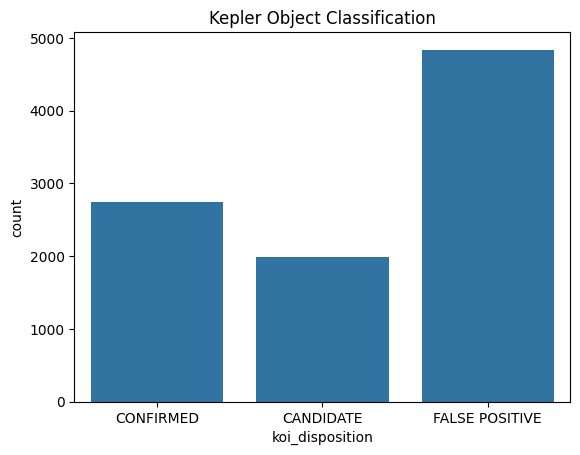

In [7]:
sns.countplot(data=df, x='koi_disposition')
plt.title('Kepler Object Classification')
plt.show()

In [8]:
# check missing values
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0].head(20)

koi_teq_err1         9564
koi_teq_err2         9564
kepler_name          6819
koi_score            1510
koi_steff_err2        483
koi_srad_err1         468
koi_steff_err1        468
koi_slogg_err2        468
koi_slogg_err1        468
koi_srad_err2         468
koi_time0bk_err1      454
koi_period_err1       454
koi_period_err2       454
koi_time0bk_err2      454
koi_impact_err1       454
koi_depth_err1        454
koi_depth_err2        454
koi_duration_err1     454
koi_duration_err2     454
koi_impact_err2       454
dtype: int64

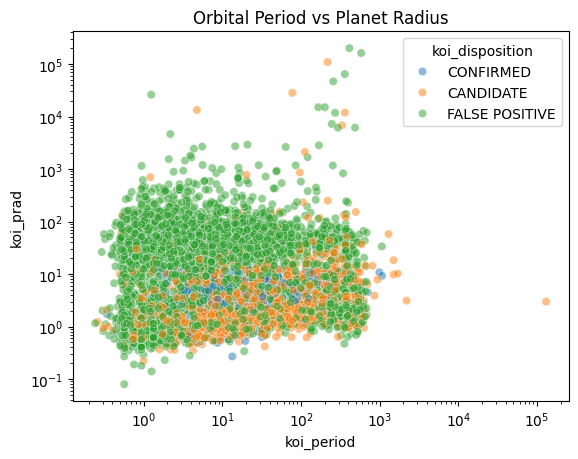

In [9]:
sns.scatterplot(
    data=df,
    x='koi_period',
    y='koi_prad',
    hue='koi_disposition',
    alpha=0.5
)

plt.xscale('log')
plt.yscale('log')
plt.title('Orbital Period vs Planet Radius')
plt.show()

In [10]:
features = [
    'koi_period',      # Orbital period
    'koi_duration',    # Transit duration
    'koi_depth',       # Transit depth
    'koi_prad',        # Estimated planet radius
    'koi_teq',         # Equilibrium temperature
    'koi_model_snr',   # Signal-to-noise ratio
    'koi_steff',       # Stellar temperature
    'koi_slogg',       # Stellar surface gravity
    'koi_srad',        # Stellar radius
    'koi_kepmag'       # Kepler magnitude
]

train_df = df[
    df['koi_disposition'].isin(['CONFIRMED', 'FALSE POSITIVE'])
].copy()

X = train_df[features]
y = (train_df['koi_disposition'] == 'CONFIRMED').astype(int)

print(X.shape)
print(y.value_counts())

(7582, 10)
koi_disposition
0    4839
1    2743
Name: count, dtype: int64


In [11]:
# splitting data

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=train_df['kepid'])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (6054, 10)
Testing: (1528, 10)


# Logistic Regression

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print(classification_report(
    y_test,
    predictions,
    target_names=['False Positive', 'Confirmed']
))

                precision    recall  f1-score   support

False Positive       0.88      0.80      0.84       968
     Confirmed       0.71      0.82      0.76       560

      accuracy                           0.81      1528
     macro avg       0.79      0.81      0.80      1528
  weighted avg       0.82      0.81      0.81      1528



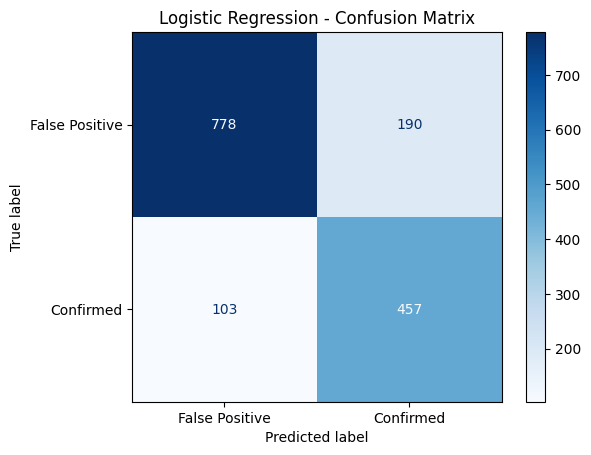

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    display_labels=['False Positive', 'Confirmed'],
    cmap='Blues'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

# Random Forest

                precision    recall  f1-score   support

False Positive       0.94      0.92      0.93       968
     Confirmed       0.87      0.90      0.89       560

      accuracy                           0.92      1528
     macro avg       0.91      0.91      0.91      1528
  weighted avg       0.92      0.92      0.92      1528



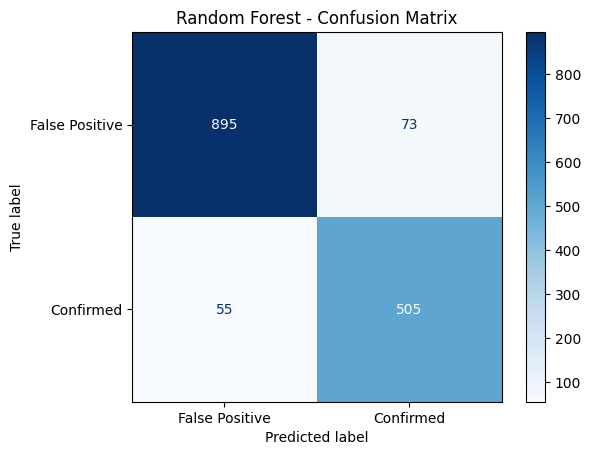

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

rf_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print(classification_report(
    y_test,
    rf_predictions,
    target_names=['False Positive', 'Confirmed']
))

ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_test,
    y_test,
    display_labels=['False Positive', 'Confirmed'],
    cmap='Blues'
)

plt.title('Random Forest - Confusion Matrix')
plt.show()

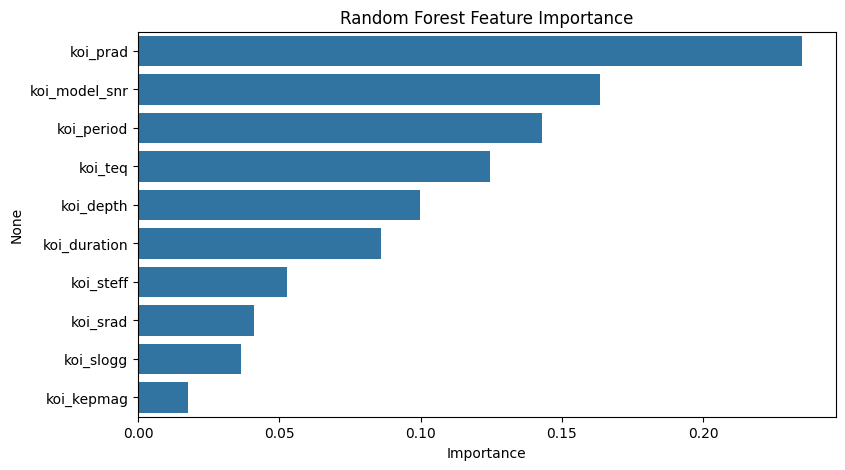

In [15]:
rf = rf_model.named_steps['randomforestclassifier']

importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.show()

planet radius plays a big role in decision making here. going to investigate whether a larger value increases or decreases the probaility of a confirmed planet later.

# Cross validation

In [16]:
from sklearn.model_selection import GroupKFold, cross_validate

groups = train_df.iloc[train_idx]['kepid']

cv = GroupKFold(n_splits=5)

scores = cross_validate(
    rf_model,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1'
    },
    n_jobs=-1
)

for metric in ['accuracy', 'precision', 'recall', 'f1']:
    values = scores[f'test_{metric}']
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

accuracy: 0.913 ± 0.002
precision: 0.872 ± 0.008
recall: 0.890 ± 0.002
f1: 0.881 ± 0.005


low variation thumbs up.

one thing to keep in mind: this shows consistency with the dataset, not necessarily generalization to new telescope surveys or real word discovery conditions.

In [17]:
# Hyperparameter tuning

In [18]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

param_grid = {
    'randomforestclassifier__n_estimators': [100, 200, 300, 500],
    'randomforestclassifier__max_depth': [5, 10, 15, 20, None],
    'randomforestclassifier__min_samples_split': [2, 5, 10],
    'randomforestclassifier__min_samples_leaf': [1, 2, 4],
    'randomforestclassifier__max_features': ['sqrt', 'log2', 0.8]
}

search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=20,
    cv=GroupKFold(n_splits=5),
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

search.fit(X_train, y_train, groups=groups)

print("Best parameters:")
print(search.best_params_)

print(f"\nBest CV F1: {search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__min_samples_leaf': 2, 'randomforestclassifier__max_features': 0.8, 'randomforestclassifier__max_depth': None}

Best CV F1: 0.8859


## evaluating tuned model

                precision    recall  f1-score   support

False Positive       0.95      0.93      0.94       968
     Confirmed       0.88      0.91      0.89       560

      accuracy                           0.92      1528
     macro avg       0.91      0.92      0.91      1528
  weighted avg       0.92      0.92      0.92      1528



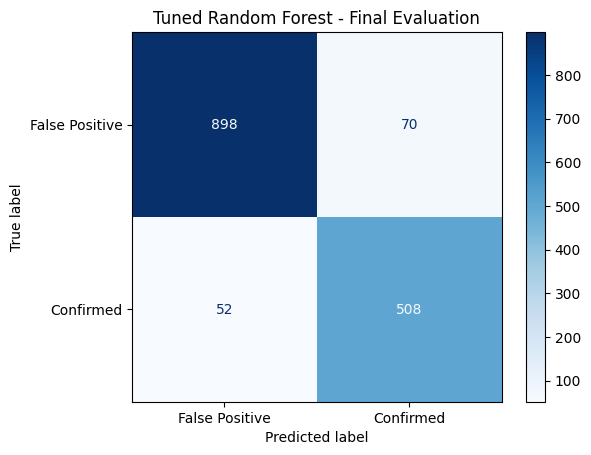

In [19]:
best_model = search.best_estimator_

predictions = best_model.predict(X_test)

print(classification_report(
    y_test,
    predictions,
    target_names=['False Positive', 'Confirmed']
))

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=['False Positive', 'Confirmed'],
    cmap='Blues'
)

plt.title('Tuned Random Forest - Final Evaluation')
plt.show()

## Permutation feature importance

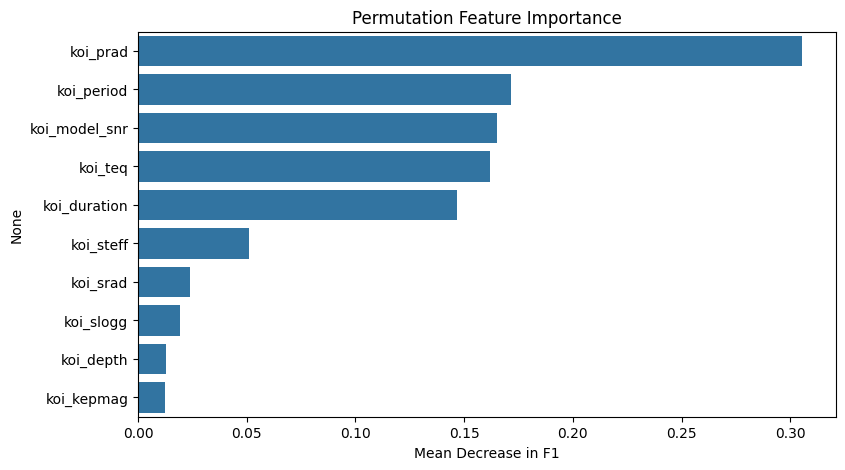

In [20]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_model,
    X_train,
    y_train,
    n_repeats=10,
    random_state=42,
    scoring='f1',
    n_jobs=-1
)

importance = pd.Series(
    result.importances_mean,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title('Permutation Feature Importance')
plt.xlabel('Mean Decrease in F1')
plt.show()

# Predicting unresolved candidates!
we have 1,982 unresolved candidates in this datasets (left them out in training). let's see how our model classifies them.

In [21]:
candidates = df[
df['koi_disposition'] == 'CANDIDATE'
].copy()

X_candidates = candidates[features]

candidates['prediction'] = best_model.predict(X_candidates)

candidates['confidence'] = best_model.predict_proba(
    X_candidates
)[:, 1]

candidates['prediction'] = candidates['prediction'].map({
    0: 'Likely False Positive',
    1: 'Likely Planet!'
})

print(candidates['prediction'].value_counts())

prediction
Likely False Positive    1486
Likely Planet!            496
Name: count, dtype: int64


In [22]:
results = candidates[[
    'kepoi_name',
    'koi_period',
    'koi_prad',
    'koi_teq',
    'prediction',
    'confidence'
]].sort_values('confidence', ascending=False)

results.head(20)

,kepoi_name,koi_period,koi_prad,koi_teq,prediction,confidence
537,K01145.01,30.587215,2.32,621.0,Likely Planet!,0.997500
744,K01315.01,6.846399,1.90,1132.0,Likely Planet!,0.997500
304,K00935.04,9.617314,1.94,1010.0,Likely Planet!,0.997500
1535,K01861.01,17.504417,3.56,824.0,Likely Planet!,0.996250
1682,K02174.01,6.693328,2.44,609.0,Likely Planet!,0.994167
458,K00994.01,4.298920,2.12,1046.0,Likely Planet!,0.989333
1549,K02009.01,86.749081,2.23,398.0,Likely Planet!,0.988500
1591,K01803.01,4.539297,2.34,830.0,Likely Planet!,0.986143
2187,K02449.01,53.358044,3.41,474.0,Likely Planet!,0.981750
3027,K00426.01,16.301413,3.84,805.0,Likely Planet!,0.980500


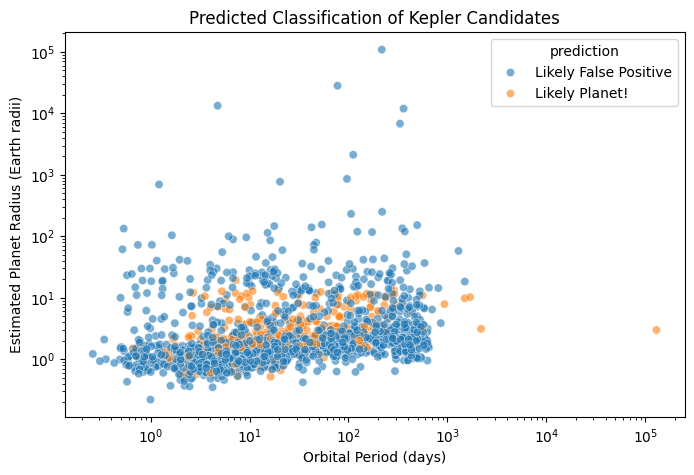

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=candidates,
    x='koi_period',
    y='koi_prad',
    hue='prediction',
    alpha=0.6
)

plt.xscale('log')
plt.yscale('log')
plt.title('Predicted Classification of Kepler Candidates')
plt.xlabel('Orbital Period (days)')
plt.ylabel('Estimated Planet Radius (Earth radii)')
plt.show()

clearly it's favoring certain regions of the parameter space.
objects with large radii tend to be classified as false positive, same with small objects.

this suggests the model is considering additional features (orbital period, signal to noise ratio)

let's see

In [24]:
compare_features = [
    'koi_prad',
    'koi_period',
    'koi_model_snr',
    'koi_teq',
    'koi_duration'
]

candidates.groupby('prediction')[compare_features].median().round(2)

,koi_prad,koi_period,koi_model_snr,koi_teq,koi_duration
prediction,,,,,
Likely False Positive,1.68,23.12,9.9,676.0,3.58
Likely Planet!,1.91,15.40,15.2,719.5,3.76


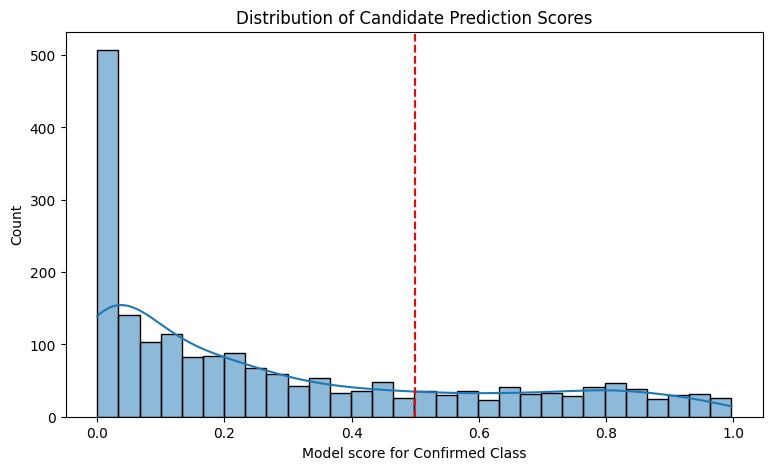

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=candidates,
    x='confidence',
    bins=30,
    kde=True
)

plt.axvline(0.5, color='red', linestyle='--')
plt.xlabel('Model score for Confirmed Class')
plt.title('Distribution of Candidate Prediction Scores')
plt.show()

potential selection bias. model might favor stronger, easier to detect transit signals. probably reasonable but raises the question:
is our model learning what makes an exoplanet or what makes one easier to confirm

probably both

# Investigating SNR (signal to noise ratio) bias

In [26]:
test_results = X_test.copy()

test_results['actual'] = y_test
test_results['predicted'] = best_model.predict(X_test)

test_results['correct'] = (
    test_results['actual'] == test_results['predicted']
)

confirmed_test = test_results[
    test_results['actual'] == 1
].copy()

confirmed_test['snr_group'] = pd.cut(
    confirmed_test['koi_model_snr'],
    bins=[0, 10, 20, 50, float('inf')],
    labels=['0-10', '10-20', '20-50', '50+']
)

summary = confirmed_test.groupby(
    'snr_group',
    observed=True
).agg(
    count=('correct', 'size'),
    recall=('correct', 'mean')
)

print(summary)

           count    recall
snr_group                 
0-10           3  0.333333
10-20        165  0.854545
20-50        236  0.940678
50+          156  0.923077


model clearly performs better on stronger transit signals